# Lab 1 — Regression

Environment verification and AAPL exploratory analysis are complete. Modeling sections remain to be implemented.


## 1. Problem definition and dataset source

Source: [NYSE on Kaggle](https://www.kaggle.com/datasets/dgawlik/nyse), `prices-split-adjusted.csv`. Predict AAPL next-trading-day split-adjusted close using current-day open, high, low, close, and volume available after market close. AAPL has complete observed date coverage; conclusions are limited to this stock.


## 2. Environment, seeds, and device

Kaggle environment setup and synthetic PyTorch/GridSearchCV smoke test.


In [29]:
%pip install -q skorch imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [30]:
import random
import platform
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Python:", platform.python_version())
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for package in [
    "torch", "scikit-learn", "skorch", "pandas",
    "numpy", "matplotlib", "seaborn", "imbalanced-learn"
]:
    print(f"{package}: {version(package)}")

Python: 3.13.15
Device: cuda
GPU: Tesla T4
torch: 2.11.0+cu128
scikit-learn: 1.6.1
skorch: 1.4.0
pandas: 2.3.3
numpy: 2.1.3
matplotlib: 3.10.0
seaborn: 0.13.2
imbalanced-learn: 0.14.2


In [31]:
from torch import nn
from skorch import NeuralNetRegressor

from sklearn.datasets import make_regression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Small synthetic regression problem for environment verification.
X_smoke, y_smoke = make_regression(
    n_samples=240,
    n_features=6,
    noise=0.1,
    random_state=SEED,
)

X_smoke = X_smoke.astype(np.float32)
y_smoke = y_smoke.astype(np.float32).reshape(-1, 1)
y_smoke /= y_smoke.std()


class SmokeMLP(nn.Module):
    def __init__(self, input_dim=6, hidden_dim=16):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, X):
        return self.network(X)


net = NeuralNetRegressor(
    module=SmokeMLP,
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    lr=0.01,
    max_epochs=20,
    batch_size=32,
    train_split=False,
    iterator_train__shuffle=True,
    device=DEVICE,
    verbose=0,
)

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("net", net),
])

search = GridSearchCV(
    estimator=pipeline,
    param_grid={"net__module__hidden_dim": [8, 16]},
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=2, shuffle=True, random_state=SEED),
    n_jobs=1,
    error_score="raise",
    refit=True,
)

search.fit(X_smoke, y_smoke)

fitted_net = search.best_estimator_.named_steps["net"]
losses = np.array(fitted_net.history[:, "train_loss"])
predictions = search.predict(X_smoke[:5])

assert np.isfinite(losses).all(), "Non-finite training loss."
assert predictions.shape == (5, 1), "Unexpected prediction shape."
assert np.isfinite(predictions).all(), "Non-finite predictions."

print("PASS: PyTorch training, GridSearchCV, and prediction.")
print("Model device:", next(fitted_net.module_.parameters()).device)
print("Best parameters:", search.best_params_)
print("Best CV MSE:", -search.best_score_)
print(f"Refit training loss: {losses[0]:.4f} → {losses[-1]:.4f}")

PASS: PyTorch training, GridSearchCV, and prediction.
Model device: cuda:0
Best parameters: {'net__module__hidden_dim': 16}
Best CV MSE: 0.008058980572968721
Refit training loss: 1.0699 → 0.0026


## 3. Load and inspect NYSE data

Inspect schema, missing values, duplicates, price validity, coverage, and AAPL selection.


In [32]:
DATA_PATH = Path(
    "/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv"
)

assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

prices = pd.read_csv(DATA_PATH)

required_columns = {
    "date", "symbol", "open", "close", "low", "high", "volume"
}
missing_columns = required_columns - set(prices.columns)

assert not missing_columns, f"Missing columns: {missing_columns}"

print("Shape:", prices.shape)
print("Number of stocks:", prices["symbol"].nunique())
print("Date range:", prices["date"].min(), "→", prices["date"].max())

display(prices.head())

Shape: (851264, 7)
Number of stocks: 501
Date range: 2010-01-04 → 2016-12-30


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [33]:
print("DATASET SIZE")
print(f"Rows: {len(prices):,}")
print(f"Columns: {prices.shape[1]}")
print(f"Stocks: {prices['symbol'].nunique():,}")

print("\nCOLUMN TYPES AND MISSING VALUES")
column_summary = pd.DataFrame({
    "dtype": prices.dtypes.astype(str),
    "missing_count": prices.isna().sum(),
    "missing_percent": prices.isna().mean().mul(100).round(3),
})
display(column_summary)

parsed_dates = pd.to_datetime(
    prices["date"],
    format="%Y-%m-%d",
    errors="coerce",
)

print("\nDATES")
print("Invalid or missing dates:", parsed_dates.isna().sum())
print("Earliest date:", parsed_dates.min())
print("Latest date:", parsed_dates.max())

print("\nDUPLICATES")
print("Fully duplicated rows:", prices.duplicated().sum())
print(
    "Extra rows with a repeated (symbol, date) key:",
    prices.duplicated(subset=["symbol", "date"]).sum(),
)

date_order = (
    prices.assign(parsed_date=parsed_dates)
    .groupby("symbol")["parsed_date"]
    .apply(lambda dates: dates.is_monotonic_increasing)
)

print("\nROW ORDER")
print("Entire file sorted by date:", parsed_dates.is_monotonic_increasing)
print("Stocks with dates in ascending order:", int(date_order.sum()))
print("Stocks requiring date sorting:", int((~date_order).sum()))

DATASET SIZE
Rows: 851,264
Columns: 7
Stocks: 501

COLUMN TYPES AND MISSING VALUES


,dtype,missing_count,missing_percent
date,object,0,0.0
symbol,object,0,0.0
open,float64,0,0.0
close,float64,0,0.0
low,float64,0,0.0
high,float64,0,0.0
volume,float64,0,0.0



DATES
Invalid or missing dates: 0
Earliest date: 2010-01-04 00:00:00
Latest date: 2016-12-30 00:00:00

DUPLICATES
Fully duplicated rows: 0
Extra rows with a repeated (symbol, date) key: 0

ROW ORDER
Entire file sorted by date: False
Stocks with dates in ascending order: 501
Stocks requiring date sorting: 0


In [34]:
stock_data = prices.copy()
stock_data["date"] = pd.to_datetime(stock_data["date"], format="%Y-%m-%d")
stock_data = stock_data.sort_values(["symbol", "date"]).reset_index(drop=True)

coverage = (
    stock_data.groupby("symbol")
    .agg(
        rows=("date", "size"),
        first_date=("date", "min"),
        last_date=("date", "max"),
    )
    .sort_values(["rows", "symbol"], ascending=[False, True])
)

print("STOCK COVERAGE")
display(coverage.head(15))

print("ROWS PER STOCK")
display(coverage["rows"].describe().to_frame("rows"))

price_columns = ["open", "close", "low", "high"]
numeric_columns = price_columns + ["volume"]

checks = pd.Series({
    "Rows with non-finite numeric values": (
        ~np.isfinite(stock_data[numeric_columns]).all(axis=1)
    ).sum(),
    "Rows with non-positive prices": (
        stock_data[price_columns] <= 0
    ).any(axis=1).sum(),
    "Rows with negative volume": (stock_data["volume"] < 0).sum(),
    "Rows with zero volume": (stock_data["volume"] == 0).sum(),
    "Rows with low above high": (
        stock_data["low"] > stock_data["high"]
    ).sum(),
    "Rows with open outside low/high": (
        (stock_data["open"] < stock_data["low"])
        | (stock_data["open"] > stock_data["high"])
    ).sum(),
    "Rows with close outside low/high": (
        (stock_data["close"] < stock_data["low"])
        | (stock_data["close"] > stock_data["high"])
    ).sum(),
})

print("DATA VALIDITY CHECKS")
display(checks.to_frame("row_count"))

STOCK COVERAGE


,rows,first_date,last_date
symbol,,,
A,1762,2010-01-04,2016-12-30
AAL,1762,2010-01-04,2016-12-30
AAP,1762,2010-01-04,2016-12-30
AAPL,1762,2010-01-04,2016-12-30
ABC,1762,2010-01-04,2016-12-30
ABT,1762,2010-01-04,2016-12-30
ACN,1762,2010-01-04,2016-12-30
ADBE,1762,2010-01-04,2016-12-30
ADI,1762,2010-01-04,2016-12-30


ROWS PER STOCK


,rows
count,501.000000
mean,1699.129741
std,253.731238
min,126.000000
25%,1762.000000
50%,1762.000000
75%,1762.000000
max,1762.000000


DATA VALIDITY CHECKS


,row_count
Rows with non-finite numeric values,0
Rows with non-positive prices,0
Rows with negative volume,0
Rows with zero volume,21
Rows with low above high,0
Rows with open outside low/high,0
Rows with close outside low/high,0


In [35]:
zero_volume_rows = stock_data.loc[
    stock_data["volume"].eq(0),
    ["symbol", "date", "open", "close", "low", "high", "volume"],
]

print("ZERO-VOLUME RECORDS")
display(zero_volume_rows)

SYMBOL = "AAPL"

stock = (
    stock_data.loc[stock_data["symbol"].eq(SYMBOL)]
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

assert not stock.empty, f"No records found for {SYMBOL}"
assert stock["date"].is_unique
assert stock["date"].is_monotonic_increasing

observed_market_dates = pd.DatetimeIndex(stock_data["date"].unique()).sort_values()
missing_dates = observed_market_dates.difference(
    pd.DatetimeIndex(stock["date"])
)

print(f"\nCANDIDATE STOCK: {SYMBOL}")
print("Rows:", len(stock))
print("First date:", stock["date"].min().date())
print("Last date:", stock["date"].max().date())
print("Zero-volume rows:", stock["volume"].eq(0).sum())
print("Dates present elsewhere in the dataset but absent for AAPL:",
      len(missing_dates))

if len(missing_dates):
    print(missing_dates.strftime("%Y-%m-%d").tolist())

print("\nFIRST RECORDS")
display(stock.head())

ZERO-VOLUME RECORDS


,symbol,date,open,close,low,high,volume
133701,CB,2016-01-15,111.019997,111.019997,111.019997,111.019997,0.0
152069,CHTR,2010-01-06,35.000000,35.000000,35.000000,35.000000,0.0
152096,CHTR,2010-02-16,29.740000,29.740000,29.740000,29.740000,0.0
152097,CHTR,2010-02-17,29.740000,29.740000,29.740000,29.740000,0.0
152099,CHTR,2010-02-19,29.700001,29.700001,29.700001,29.700001,0.0
152101,CHTR,2010-02-23,29.700001,29.700001,29.700001,29.700001,0.0
152102,CHTR,2010-02-24,29.700001,29.700001,29.700001,29.700001,0.0
152132,CHTR,2010-04-08,34.549999,34.549999,34.549999,34.549999,0.0
152135,CHTR,2010-04-13,35.000000,35.000000,35.000000,35.000000,0.0
152140,CHTR,2010-04-20,36.009998,36.009998,36.009998,36.009998,0.0



CANDIDATE STOCK: AAPL
Rows: 1762
First date: 2010-01-04
Last date: 2016-12-30
Zero-volume rows: 0
Dates present elsewhere in the dataset but absent for AAPL: 0

FIRST RECORDS


,date,symbol,open,close,low,high,volume
0,2010-01-04,AAPL,30.490000,30.572857,30.340000,30.642857,123432400.0
1,2010-01-05,AAPL,30.657143,30.625713,30.464285,30.798571,150476200.0
2,2010-01-06,AAPL,30.625713,30.138571,30.107143,30.747143,138040000.0
3,2010-01-07,AAPL,30.250000,30.082857,29.864286,30.285715,119282800.0
4,2010-01-08,AAPL,30.042856,30.282858,29.865715,30.285715,111902700.0


## 4. Chronological splits and exploratory analysis

Define next-day targets and chronological partitions; explore training data only and verify partition boundaries.


In [36]:
FEATURES = ["open", "high", "low", "close", "volume"]
TARGET = "next_close"

supervised = stock.copy()
supervised[TARGET] = supervised["close"].shift(-1)
supervised["target_date"] = supervised["date"].shift(-1)
supervised = supervised.dropna(subset=[TARGET, "target_date"]).copy()

validation_start = pd.Timestamp("2015-01-01")
test_start = pd.Timestamp("2016-01-01")

train = supervised.loc[
    supervised["target_date"] < validation_start
].copy()

validation = supervised.loc[
    (supervised["date"] >= validation_start)
    & (supervised["target_date"] < test_start)
].copy()

test = supervised.loc[
    supervised["date"] >= test_start
].copy()

assert all(len(part) > 0 for part in [train, validation, test])
assert train["target_date"].max() < validation["date"].min()
assert validation["target_date"].max() < test["date"].min()
assert (supervised["target_date"] > supervised["date"]).all()

split_summary = pd.DataFrame([
    {
        "split": name,
        "samples": len(part),
        "first_input_date": part["date"].min(),
        "last_input_date": part["date"].max(),
        "first_target_date": part["target_date"].min(),
        "last_target_date": part["target_date"].max(),
    }
    for name, part in [
        ("train", train),
        ("validation", validation),
        ("test", test),
    ]
]).set_index("split")

display(split_summary)

excluded = len(supervised) - len(train) - len(validation) - len(test)
print("Examples excluded at split boundaries:", excluded)
print("Input features:", FEATURES)
print("Target:", TARGET)

,samples,first_input_date,last_input_date,first_target_date,last_target_date
split,,,,,
train,1257,2010-01-04,2014-12-30,2010-01-05,2014-12-31
validation,251,2015-01-02,2015-12-30,2015-01-05,2015-12-31
test,251,2016-01-04,2016-12-29,2016-01-05,2016-12-30


Examples excluded at split boundaries: 2
Input features: ['open', 'high', 'low', 'close', 'volume']
Target: next_close


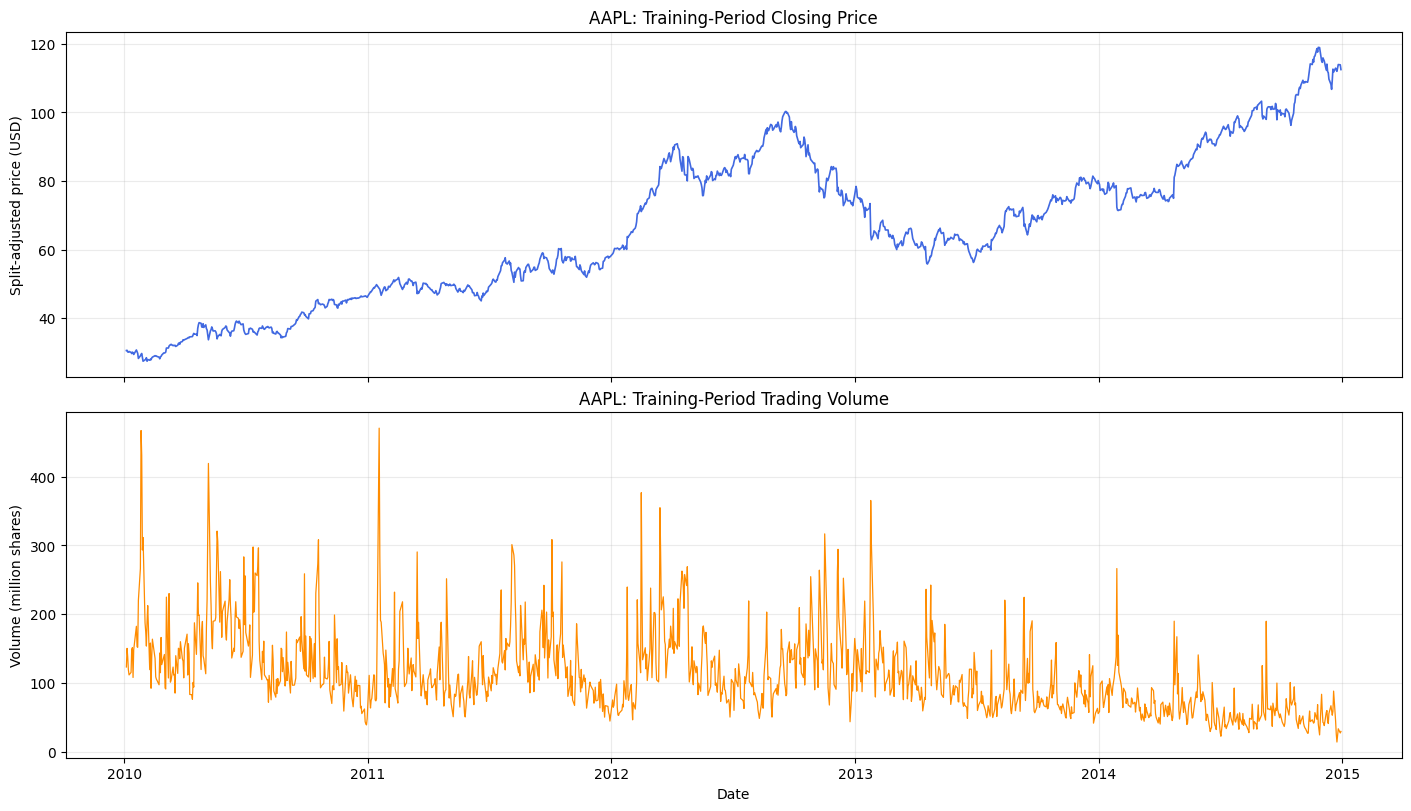

In [37]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

PLOT_DIR = Path("/kaggle/working/plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True, constrained_layout=True
)

axes[0].plot(
    train["date"],
    train["close"],
    color="royalblue",
    linewidth=1.2,
)
axes[0].set_title(f"{SYMBOL}: Training-Period Closing Price")
axes[0].set_ylabel("Split-adjusted price (USD)")
axes[0].grid(alpha=0.25)

axes[1].plot(
    train["date"],
    train["volume"] / 1_000_000,
    color="darkorange",
    linewidth=0.9,
)
axes[1].set_title(f"{SYMBOL}: Training-Period Trading Volume")
axes[1].set_ylabel("Volume (million shares)")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.25)

axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.savefig(
    PLOT_DIR / "aapl_training_price_volume.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

,count,mean,std,min,1%,25%,50%,75%,99%,max
open,1257.0,6.620000e+01,21.62,27.48,28.66,48.88,6.494000e+01,8.207000e+01,1.141700e+02,1.192700e+02
high,1257.0,6.680000e+01,21.80,28.00,28.91,49.24,6.538000e+01,8.247000e+01,1.157100e+02,1.197500e+02
low,1257.0,6.553000e+01,21.45,27.18,28.15,48.36,6.418000e+01,8.129000e+01,1.129900e+02,1.180500e+02
close,1257.0,6.618000e+01,21.62,27.44,28.56,48.81,6.471000e+01,8.174000e+01,1.143800e+02,1.190000e+02
volume,1257.0,1.139543e+08,59640235.51,14479600.00,32842360.00,71766800.00,1.010128e+08,1.414658e+08,3.069510e+08,4.702495e+08


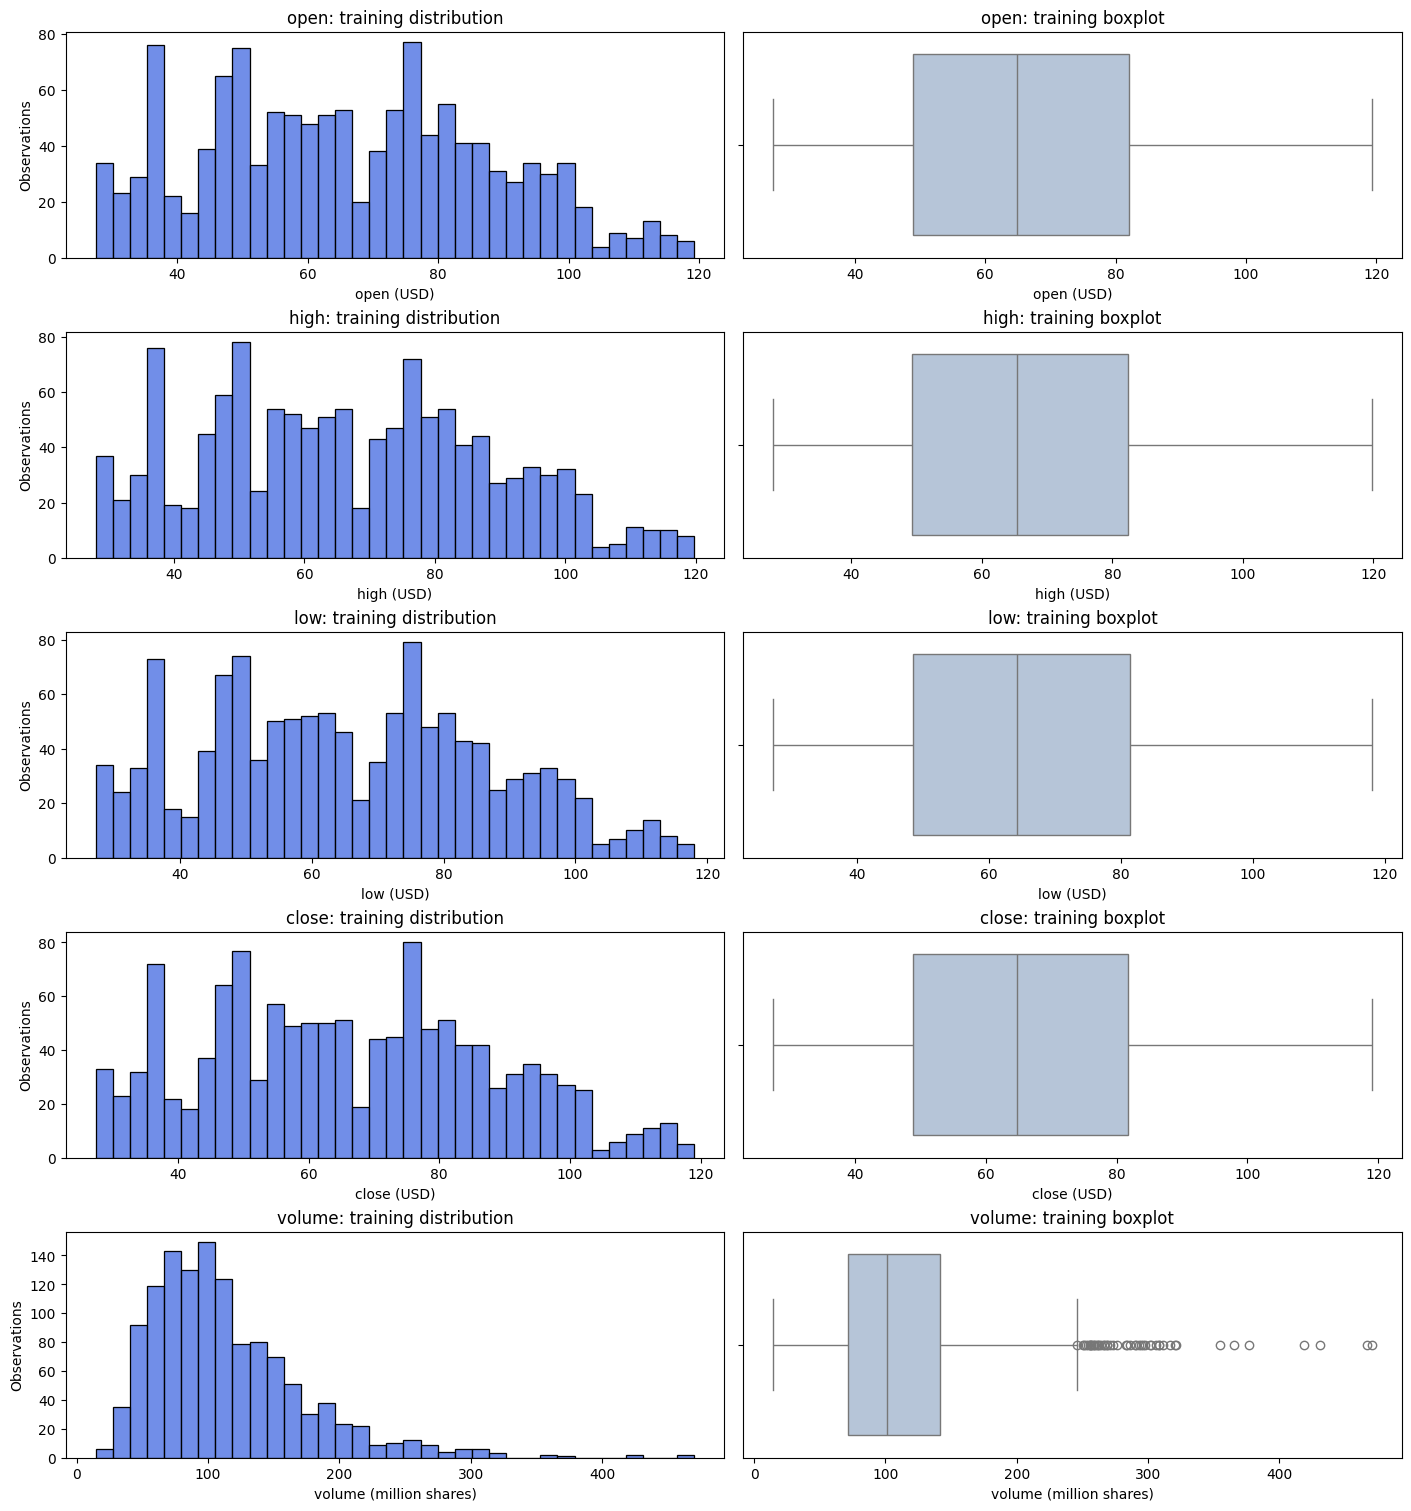

In [38]:
import seaborn as sns

display(
    train[FEATURES]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    .T.round(2)
)

fig, axes = plt.subplots(
    len(FEATURES),
    2,
    figsize=(14, 15),
    constrained_layout=True,
)

for row, feature in enumerate(FEATURES):
    values = train[feature]
    unit = "USD"

    if feature == "volume":
        values = values / 1_000_000
        unit = "million shares"

    sns.histplot(
        x=values,
        bins=35,
        ax=axes[row, 0],
        color="royalblue",
    )
    axes[row, 0].set_title(f"{feature}: training distribution")
    axes[row, 0].set_xlabel(f"{feature} ({unit})")
    axes[row, 0].set_ylabel("Observations")

    sns.boxplot(
        x=values,
        ax=axes[row, 1],
        color="lightsteelblue",
        whis=1.5,
    )
    axes[row, 1].set_title(f"{feature}: training boxplot")
    axes[row, 1].set_xlabel(f"{feature} ({unit})")

fig.savefig(
    PLOT_DIR / "aapl_training_distributions_boxplots.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

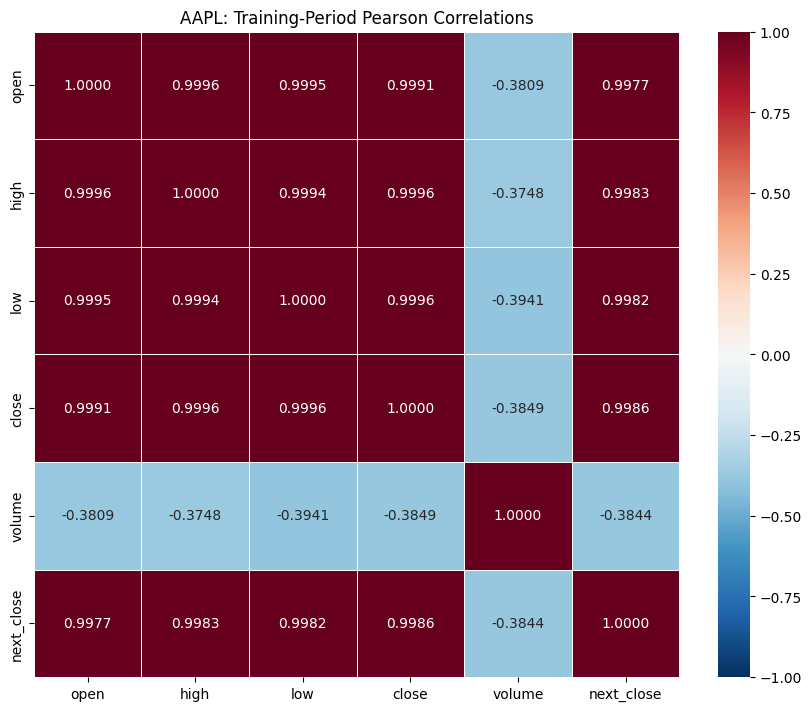

FEATURE CORRELATIONS WITH NEXT-DAY CLOSE


,pearson_correlation
close,0.998624
high,0.998253
low,0.998212
open,0.997717
volume,-0.384437


In [39]:
correlation_columns = FEATURES + [TARGET]
correlations = train[correlation_columns].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)

sns.heatmap(
    correlations,
    annot=True,
    fmt=".4f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title(f"{SYMBOL}: Training-Period Pearson Correlations")

fig.savefig(
    PLOT_DIR / "aapl_training_correlations.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("FEATURE CORRELATIONS WITH NEXT-DAY CLOSE")
display(
    correlations.loc[FEATURES, TARGET]
    .sort_values(ascending=False)
    .to_frame("pearson_correlation")
    .round(6)
)

TRAINING NEXT-DAY CHANGE (%)


,next_day_change_pct
count,1257.000
mean,0.116
std,1.679
min,-12.356
1%,-4.238
5%,-2.499
50%,0.100
95%,2.645
99%,4.780
max,8.874


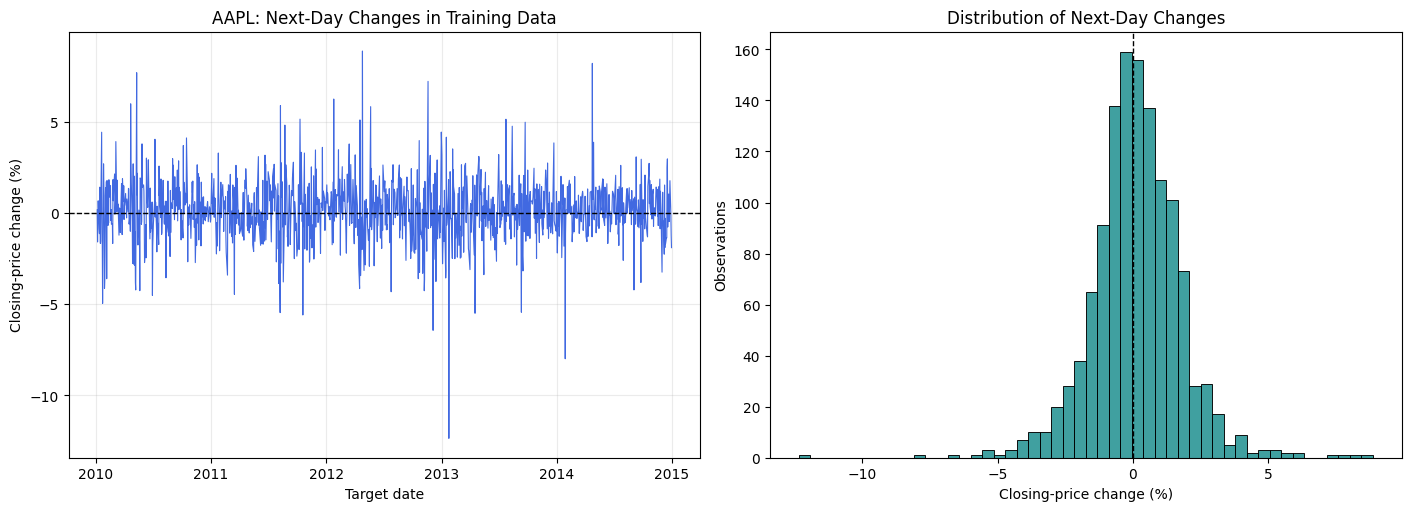

In [40]:
next_day_change_pct = (
    (train[TARGET] / train["close"]) - 1
) * 100

print("TRAINING NEXT-DAY CHANGE (%)")
display(
    next_day_change_pct.describe(
        percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
    ).to_frame("next_day_change_pct").round(3)
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), constrained_layout=True
)

axes[0].plot(
    train["target_date"],
    next_day_change_pct,
    color="royalblue",
    linewidth=0.8,
)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title(f"{SYMBOL}: Next-Day Changes in Training Data")
axes[0].set_xlabel("Target date")
axes[0].set_ylabel("Closing-price change (%)")
axes[0].grid(alpha=0.25)
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

sns.histplot(
    x=next_day_change_pct,
    bins=50,
    color="teal",
    ax=axes[1],
)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Distribution of Next-Day Changes")
axes[1].set_xlabel("Closing-price change (%)")
axes[1].set_ylabel("Observations")

fig.savefig(
    PLOT_DIR / "aapl_training_next_day_changes.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### EDA conclusions

- The NYSE dataset contains 851,264 rows, seven columns, and 501 stocks.
  No missing values, invalid dates, duplicate stock/date records, or
  inconsistent OHLC price relationships were found.
- There are 21 zero-volume records across other stocks. AAPL has none
  and covers all 1,762 trading dates observed in the dataset.
  
- This experiment uses AAPL only. Its conclusions therefore cannot
  automatically be generalized to other stocks.

### Prediction task and chronological splits

Predict the next trading day's split-adjusted closing price after the
current day's market close.

Inputs: current-day open, high, low, close, and volume.
Target: next_close. The date, symbol, target_date, and next_close are
excluded from model inputs.

| Partition | Period | Samples |
|---|---|---:|
| Training | 2010–2014 | 1,257 |
| Validation | 2015 | 251 |
| Test | 2016 | 251 |

The final observation has no next-day target and is excluded.
Two additional examples are excluded because their targets cross
partition boundaries. No random shuffling is used for these splits.
Distribution and relationship analysis uses training data only.

### Main findings

- Closing prices show an overall upward trend, interrupted by a
  substantial decline from late 2012 into 2013.
- Open, high, low, and close have very similar distributions and
  correlations above 0.999 with one another.
- Volume is right-skewed and has a much larger numerical scale than
  prices. High-volume observations are retained.
- Today's close correlates strongly with next-day close (0.998624).
  This does not demonstrate useful forecasting performance:
  the model must be compared with a persistence baseline.
- Next-day percentage changes average approximately 0.116%, with a
  standard deviation of 1.679 percentage points. The middle 90%
  range from approximately −2.499% to +2.645%.
- Extreme next-day changes range from −12.356% to +8.874%.
  These observations are retained rather than automatically removed.

### Modeling decisions

- Begin with the five specified input features.
- Fit preprocessing only on training data, including within CV folds.
- Compare the MLP with the baseline: tomorrow's predicted close
  equals today's close.
- Use validation results for model selection and keep the test set
  reserved for final reporting.
- Evaluate regression with MAE, RMSE, and R².

In [41]:
partitions = {
    "train": train,
    "validation": validation,
    "test": test,
}

for name, part in partitions.items():
    assert part["date"].is_monotonic_increasing, name
    assert part["date"].is_unique, name
    assert (part["target_date"] > part["date"]).all(), name
    assert part[FEATURES + [TARGET]].notna().all().all(), name

assert set(train.index).isdisjoint(validation.index)
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)

assert train["target_date"].max() < validation["date"].min()
assert validation["target_date"].max() < test["date"].min()

assert TARGET not in FEATURES
assert "target_date" not in FEATURES

expected = stock.set_index("date")["close"].shift(-1)
for name, part in partitions.items():
    np.testing.assert_allclose(
        part[TARGET].to_numpy(),
        expected.loc[part["date"]].to_numpy(),
        rtol=0,
        atol=0,
        err_msg=f"Incorrect next-day target in {name}",
    )

included_indices = train.index.union(validation.index).union(test.index)
excluded_boundaries = supervised.loc[
    ~supervised.index.isin(included_indices),
    ["date", "target_date", "close", TARGET],
]

RESULTS_DIR = Path("/kaggle/working/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

split_summary.to_csv(
    RESULTS_DIR / "aapl_split_summary.csv",
    date_format="%Y-%m-%d",
)

excluded_boundaries.to_csv(
    RESULTS_DIR / "aapl_excluded_boundary_rows.csv",
    index=False,
    date_format="%Y-%m-%d",
)

display(split_summary)
print("EXCLUDED BOUNDARY EXAMPLES")
display(excluded_boundaries)

print("PASS: disjoint partitions, chronological boundaries, and target alignment.")
print("Split records saved to:", RESULTS_DIR)

,samples,first_input_date,last_input_date,first_target_date,last_target_date
split,,,,,
train,1257,2010-01-04,2014-12-30,2010-01-05,2014-12-31
validation,251,2015-01-02,2015-12-30,2015-01-05,2015-12-31
test,251,2016-01-04,2016-12-29,2016-01-05,2016-12-30


EXCLUDED BOUNDARY EXAMPLES


,date,target_date,close,next_close
1257,2014-12-31,2015-01-02,110.379997,109.330002
1509,2015-12-31,2016-01-04,105.260002,105.349998


PASS: disjoint partitions, chronological boundaries, and target alignment.
Split records saved to: /kaggle/working/results


## 5. Training-only preprocessing and persistence baseline

TODO: implement and document this section.


## 6. Baseline PyTorch MLP

TODO: implement and document this section.


## 7. GridSearchCV with skorch and TimeSeriesSplit

TODO: implement and document this section.


## 8. Controlled regularization comparisons

TODO: implement and document this section.


## 9. Frozen-model train/test curves and final metrics

TODO: implement and document this section.


## 10. Interpretation and exported results

TODO: implement and document this section.
